# 하네스와 일곱 기능

**이 노트북에서 할 일**

1. 함수 `create_agent`와 함수 `create_deep_agent`로 에이전트 그래프를 만들어, 노드와 도구를 견줍니다.
2. 인자를 하나씩 바꿔 만들고, 기본 Deep Agent에 더해진 노드와 도구를 봅니다.
3. 기본으로 붙는 서브에이전트에 호출 한도를 주는 설정을 만들고, 모델 요청 없이 확인합니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델 객체를 만들려면 키가 필요하지만, 이 노트북은 모델에게 요청을 한 번도 보내지 않습니다.
그래서 모델 요청 수는 0번이고, 예상 비용도 0달러입니다.
출력은 모두 코드가 조립한 구조의 이름과 값입니다.

걸린 시간은 재지 않았습니다.
읽거나 쓰는 파일은 없습니다.
이 절은 앞 챕터에서 배운 함수를 쓰지 않아, 가져오는 도구 파일도 없습니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 deepagents 0.7.0과 langchain 1.4.0입니다.
나머지 셋은 `langchain-openai` 1.6.0, `langgraph` 1.2.11, `python-dotenv` 1.2.3입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~3절을 읽습니다.
두 함수가 같은 종류의 그래프를 만들고, 기본 도구가 미들웨어에서 온다는 것을 보는 자리입니다.
4~6절은 인자를 하나씩 바꾸는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch27-deepagents`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 파란 상자 create_deep_agent 모델 객체만 넘김에서 기본 미들웨어 다섯 차례는 소스 확인이라는 칸으로 화살표가 갑니다. 칸 안에는 위에서 아래로 노란 상자 FilesystemMiddleware 도구 여덟 파일 도구 일곱과 execute, 노란 상자 SubAgentMiddleware 도구 task general-purpose, 회색 상자 SummarizationMiddleware 노드와 도구 없음 소스로만 확인, 노란 상자 PatchToolCallsMiddleware 노드 before_agent, 회색 상자 AnthropicPromptCachingMiddleware 이 과정 모델에서는 하는 일 없음 소스로만 확인이 있습니다. 칸에서 맨 아래 노란 상자 create_agent가 만든 그래프 CompiledStateGraph 실행 한도 9999로 화살표가 가는 그림](attachment:01-1-미리-골라-붙인-미들웨어.png)

위에서 아래로 읽습니다.
파란 상자는 우리가 부른 함수이고, 칸 안 상자 다섯은 설치판이 붙이는 기본 미들웨어의 차례입니다.
노란 상자 안의 도구와 노드는 노트북 2·3절 출력으로 확인한 값이고, 미들웨어 이름과 차례는 설치판 소스로 확인했습니다.
회색 상자는 출력에 아무것도 남기지 않아, 설치판 소스로만 확인한 미들웨어입니다.
맨 아래 상자는 결과가 create_agent가 만든 그래프와 같은 종류이고, 실행 한도도 같다는 뜻입니다.
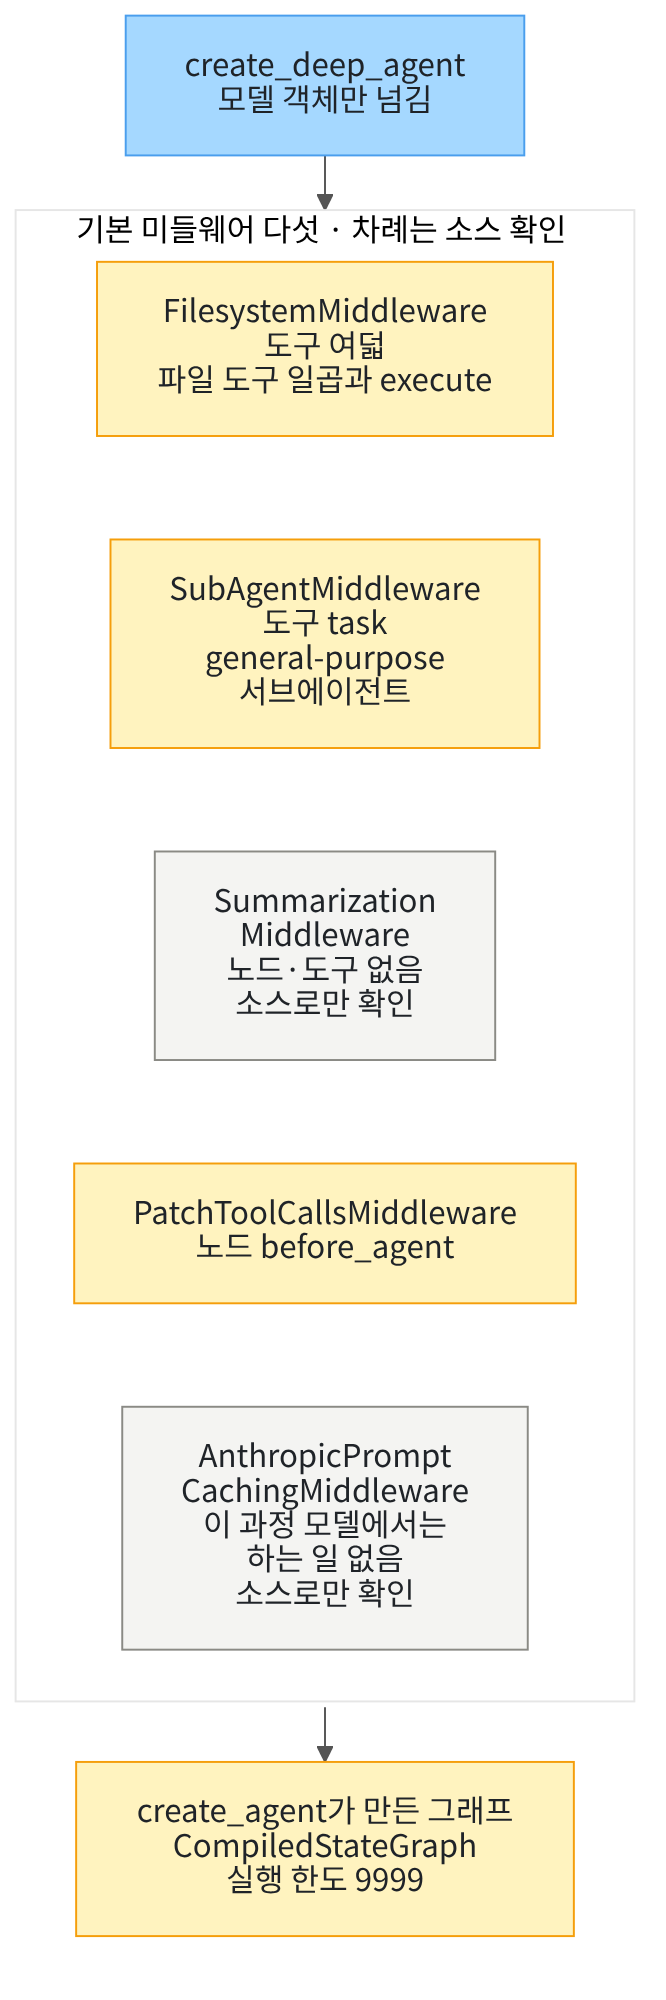

## 1. 준비

이 절에서는 에이전트에 여러 기능을 미리 붙여 주는 함수를 처음 씁니다.
절 제목의 하네스는 Ch 6 01절에서 정의한 말이고, 본문 「핵심 개념」에서 그 정의를 이어 씁니다.

첫 셀은 패키지 다섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "deepagents==0.7.0" "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("deepagents:", version("deepagents"))
print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
deepagents: 0.7.0
langchain: 1.4.0


langchain-openai: 1.6.0
langgraph: 1.2.11
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `deepagents: 0.7.0`과 `langchain: 1.4.0`이 보입니다.
다섯 판 모두 실습 폴더 잠금과 같은 판입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
함수 `create_deep_agent`와 미들웨어 `FilesystemMiddleware`는 패키지 deepagents에 들어 있습니다.
함수 `create_agent`는 Ch 21 01절, 미들웨어 `ModelCallLimitMiddleware`는 Ch 22 04절에서 썼습니다.
상태 형식을 만드는 이름은 Ch 13 01·04절, 손으로 만드는 응답 `AIMessage`는 Ch 20 01절에서 썼습니다.

In [2]:
# Deep Agents(이 절 처음)·에이전트(Ch 21 01절)·미들웨어(Ch 22)·모델(Ch 6 01절) 이름을 가져옵니다
from deepagents import FilesystemMiddleware, FilesystemPermission, create_deep_agent
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware, TodoListMiddleware
from langchain.chat_models import init_chat_model
# 6절의 작은 그래프에 쓸 이름입니다(상태 형식 Ch 13 01·04절, 손으로 만든 응답 Ch 20 01절)
from typing import Annotated
from typing_extensions import TypedDict
from langchain.messages import AIMessage, AnyMessage
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages

print("가져온 Deep Agents 이름:", "create_deep_agent, FilesystemMiddleware, FilesystemPermission")

가져온 Deep Agents 이름: create_deep_agent, FilesystemMiddleware, FilesystemPermission


**결과 읽기** — 출력 줄 `가져온 Deep Agents 이름: create_deep_agent, FilesystemMiddleware, FilesystemPermission`이 보입니다.
권한 규칙 `FilesystemPermission`은 4절에서, 미들웨어 `TodoListMiddleware`는 5절에서 씁니다.
이 절은 앞 챕터에서 배운 함수를 쓰지 않아, 도구 파일에서 가져오는 줄이 없습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
이 셀은 모델 객체만 만들고, 모델 요청은 보내지 않습니다.
이 절의 다른 셀도 에이전트를 만들기만 하고 모델을 부르지 않습니다.

에이전트를 만드는 두 함수에는 이 모델 객체를 그대로 넘깁니다.
Deep Agents에 모델 이름 글자만 넘기면, temperature 설정이 없는 모델을 새로 만들기 때문입니다.
이 사실은 설치판 소스로 확인했고, 본문 「주의할 점」에 적었습니다.

## 2. 같은 틀에서 시작하기

Ch 21 01절에서는 함수 `create_agent`로 에이전트 그래프를 만들었습니다.
먼저 같은 모양으로 도구 없는 에이전트를 하나 만들고, 그래프의 노드 이름을 봅니다.

In [5]:
# Ch 21 01절처럼 도구 없는 에이전트를 만들고, 종류와 노드 이름을 봅니다(요청은 보내지 않음)
plain_agent = create_agent(model, tools=[])
plain_graph = plain_agent.get_graph()
plain_nodes = list(plain_graph.nodes)
print("만든 것의 종류:", type(plain_agent).__name__)
print("create_agent의 노드:", plain_nodes)

만든 것의 종류: CompiledStateGraph
create_agent의 노드: ['__start__', 'model', '__end__']


**결과 읽기** — 출력 줄 `만든 것의 종류: CompiledStateGraph`와 `create_agent의 노드: ['__start__', 'model', '__end__']`가 보입니다.
도구가 없어서 도구 실행 노드 `tools`가 없습니다.
Ch 26 01절의 대출 규정 담당과 같은 모양입니다.

이번에는 같은 모델 객체를 함수 `create_deep_agent`에 넘깁니다.
이 함수가 만든 에이전트 그래프를 이 챕터에서는 Deep Agent라고 부릅니다.
인자 `model=`에만 모델 객체를 넘기고, 다른 인자는 주지 않습니다.
실행 전에 예상해 봅니다.
도구를 하나도 넘기지 않았으니, 노드도 앞 셀처럼 셋일까요?

In [6]:
# 같은 모델 객체로 Deep Agent를 만들고, 종류와 노드 이름을 봅니다(요청은 보내지 않음)
deep_agent = create_deep_agent(model=model)
deep_graph = deep_agent.get_graph()
deep_nodes = list(deep_graph.nodes)
print("만든 것의 종류:", type(deep_agent).__name__)
print("create_deep_agent의 노드:", deep_nodes)

만든 것의 종류: CompiledStateGraph
create_deep_agent의 노드: ['__start__', 'model', 'tools', 'PatchToolCallsMiddleware.before_agent', '__end__']


**결과 읽기** — 출력 줄 `만든 것의 종류: CompiledStateGraph`는 앞 셀과 같습니다.
라벨 `create_deep_agent의 노드:` 뒤에는 `'tools'`와 `'PatchToolCallsMiddleware.before_agent'`가 더 있습니다.
도구를 넘기지 않았는데도 도구 실행 노드가 생겼습니다.

노드 이름 `PatchToolCallsMiddleware.before_agent`는 미들웨어 이름과 훅 이름을 점으로 이은 것입니다.
Ch 22 01절의 노드형 훅(`before_agent` 등)을 가진 미들웨어는 이렇게 그래프의 노드가 됩니다.
감싸기형 훅(이름이 `wrap_`으로 시작)만 가진 미들웨어는 노드로 보이지 않습니다.
이 미들웨어는 짝이 되는 도구 메시지가 없는 도구 요청에, 취소 알림 도구 메시지를 채웁니다.
이 일은 설치판 소스로 확인했고, 이 절에서는 실행하지 않았습니다.

다음 셀은 두 그래프에 묶인 실행 한도를 봅니다.

In [7]:
# 두 그래프에 묶여 있는 실행 한도(Ch 20 03절)를 봅니다
plain_limit = plain_agent.config["recursion_limit"]
deep_limit = deep_agent.config["recursion_limit"]
print("create_agent의 실행 한도:", plain_limit)
print("create_deep_agent의 실행 한도:", deep_limit)

create_agent의 실행 한도: 9999
create_deep_agent의 실행 한도: 9999


**결과 읽기** — 출력 줄 `create_agent의 실행 한도: 9999`와 `create_deep_agent의 실행 한도: 9999`가 보입니다.
Ch 26 01절에서 본 기본 실행 한도가 Deep Agent에도 그대로 있습니다.
설치판 deepagents 0.7.0 `graph.py` 922~944행에서 함수 `create_deep_agent`는 마지막에 `create_agent`를 부릅니다.
그리고 만든 그래프에 실행 한도 9999를 다시 붙입니다.

## 3. 기본 도구는 미들웨어가 붙입니다

Deep Agent의 도구 실행 노드에 어떤 도구가 들었는지 봅니다.
다음 셀은 에이전트 그래프에서 도구 이름을 모으는 함수를 만듭니다.
컴파일한 그래프의 속성 `nodes`는 노드 이름으로 노드를 찾는 딕셔너리입니다.
찾은 노드의 속성 `bound`가 그 안에 든 도구 실행 노드(Ch 20 01절)입니다.

In [8]:
# 에이전트 그래프의 도구 실행 노드에서 도구 이름을 모아, 알파벳 차례로 내놓습니다
def tool_names(agent):
    tool_node = agent.nodes["tools"].bound
    # 도구 찾기 표 tools_by_name(Ch 20 01절)의 키가 도구 이름입니다
    names = list(tool_node.tools_by_name)
    names.sort()
    return names

**결과 읽기** — 정의 셀이라 출력이 없습니다.
목록 메서드 `sort`는 이름을 알파벳 차례로 늘어놓아, 두 목록을 나란히 읽게 해 줍니다.
도구 실행 노드가 없는 그래프에 이 함수를 부르면, 키 `tools`가 없어 멈춥니다.
그래서 2절의 `plain_agent`에는 부르지 않습니다.

다음 셀은 Deep Agent의 도구 수와 이름을 봅니다.

In [9]:
# Deep Agent가 기본으로 가진 도구의 수와 이름을 봅니다
deep_tools = tool_names(deep_agent)
print("도구 수:", len(deep_tools))
print("도구 이름:", deep_tools)

도구 수: 9
도구 이름: ['delete', 'edit_file', 'execute', 'glob', 'grep', 'ls', 'read_file', 'task', 'write_file']


**결과 읽기** — 출력 줄 `도구 수: 9`가 보입니다.
도구 일곱(`ls`·`read_file`·`write_file`·`edit_file`·`delete`·`glob`·`grep`)은 파일을 보고 쓰는 도구입니다.
도구 `execute`는 명령을 실행하는 도구이고, 도구 `task`는 서브에이전트에게 일을 맡기는 도구입니다.
우리는 도구를 하나도 넘기지 않았으니, 아홉 모두 Deep Agents가 붙인 것입니다.

이 도구들이 어디서 왔는지 봅니다.
Ch 22에서는 함수 `create_agent`에 미들웨어를 붙여 훅을 끼워 넣었습니다.
미들웨어는 훅뿐 아니라 도구도 가질 수 있습니다.
다음 셀은 함수 `create_agent`에 Deep Agents의 미들웨어 `FilesystemMiddleware` 하나만 붙입니다.

In [10]:
# Ch 22처럼 create_agent에 미들웨어 하나만 붙여 만들고, 도구와 노드를 봅니다(요청은 보내지 않음)
fs_agent = create_agent(model, tools=[], middleware=[FilesystemMiddleware()])
fs_tools = tool_names(fs_agent)
fs_graph = fs_agent.get_graph()
fs_nodes = list(fs_graph.nodes)
print("도구 수:", len(fs_tools))
print("도구 이름:", fs_tools)
print("노드:", fs_nodes)

도구 수: 8
도구 이름: ['delete', 'edit_file', 'execute', 'glob', 'grep', 'ls', 'read_file', 'write_file']
노드: ['__start__', 'model', 'tools', '__end__']


**결과 읽기** — 출력 줄 `도구 수: 8`과 `노드: ['__start__', 'model', 'tools', '__end__']`가 보입니다.
미들웨어 하나를 붙이자 함수 `create_agent`가 만든 그래프에도 도구 실행 노드와 도구 여덟이 생겼습니다.
파일을 보고 쓰는 도구 일곱을 이 챕터에서는 파일 도구라고 부릅니다.
이 미들웨어는 파일 도구 일곱과 명령 실행 도구 `execute`를 함께 붙입니다.

두 목록의 차이를 볼 함수를 만듭니다.
둘째 목록을 차례로 돌며, 첫째 목록에 없는 이름만 모읍니다.

In [11]:
# 둘째 목록에만 있는 이름을 차례대로 모아 내놓습니다
def names_only_in(base, other):
    found = []
    for name in other:
        if name not in base:
            found.append(name)
    return found

**결과 읽기** — 정의 셀이라 출력이 없습니다.
첫째 목록에 이미 있는 이름은 건너뛰어, 더해진 이름만 남습니다.

다음 셀은 미들웨어 하나만 붙인 그래프와 견주어, Deep Agent에만 있는 도구와 노드를 봅니다.

In [12]:
# 미들웨어 하나만 붙인 에이전트와 견주어, Deep Agent에만 있는 도구와 노드를 봅니다
extra_tools = names_only_in(fs_tools, deep_tools)
extra_nodes = names_only_in(fs_nodes, deep_nodes)
print("Deep Agent에만 있는 도구:", extra_tools)
print("Deep Agent에만 있는 노드:", extra_nodes)

Deep Agent에만 있는 도구: ['task']
Deep Agent에만 있는 노드: ['PatchToolCallsMiddleware.before_agent']


**결과 읽기** — 출력 줄 `Deep Agent에만 있는 도구: ['task']`와 `Deep Agent에만 있는 노드: ['PatchToolCallsMiddleware.before_agent']`가 보입니다.
도구 `task`는 Deep Agents의 서브에이전트 미들웨어(`SubAgentMiddleware`)가 붙입니다.
노드는 2절에서 본 짝 맞추기 미들웨어의 훅입니다.
함수 `create_deep_agent`는 이렇게 `create_agent`에 미들웨어를 미리 골라 붙여 그래프를 만듭니다.

설치판 소스로 보면 기본 미들웨어는 다섯이고, 차례는 파일·서브에이전트·요약·짝 맞추기·Anthropic 모델용입니다.
요약 미들웨어(`SummarizationMiddleware`)는 감싸기형 훅만 있고 도구도 없어, 이 절의 출력에 보이지 않습니다.
맨 끝의 Anthropic 모델용 미들웨어(`AnthropicPromptCachingMiddleware`)는 Anthropic 모델에서만 일합니다.
이 과정 모델에서는 아무 일도 하지 않고, 노드도 도구도 남기지 않습니다.
미들웨어 이름과 차례는 설치판 `graph.py` 816~860행으로만 확인했습니다.

다음 셀은 도구 `task`가 받는 인자와, 모델이 받을 설명 글을 봅니다.

In [13]:
# 도구 task의 인자 이름과, 모델이 받을 설명 글에 기본 서브에이전트 이름이 있는지 봅니다
deep_tool_node = deep_agent.nodes["tools"].bound
task_tool = deep_tool_node.tools_by_name["task"]
print("task 도구의 인자:", list(task_tool.args))
print("설명 글에 general-purpose가 있는가:", "general-purpose" in task_tool.description)

task 도구의 인자: ['description', 'subagent_type']
설명 글에 general-purpose가 있는가: True


**결과 읽기** — 출력 줄 `task 도구의 인자: ['description', 'subagent_type']`와 `설명 글에 general-purpose가 있는가: True`가 보입니다.
인자 `description`은 맡길 일의 글이고, 인자 `subagent_type`은 맡을 서브에이전트의 이름입니다.
서브에이전트를 하나도 넘기지 않았는데, 이름이 `general-purpose`인 서브에이전트가 설명 글에 올라 있습니다.
이 서브에이전트를 이 챕터에서는 general-purpose 서브에이전트라고 부릅니다.

설치판 `graph.py` 750~814행에서 이 서브에이전트는 따로 막지 않는 한 늘 붙습니다.
도구는 우리가 넘긴 도구와 파일 도구를 받고, 호출 한도는 없습니다.
이 점은 6절에서 다시 다룹니다.

## 4. 인자를 하나씩 바꿔 조립 결과 보기

함수 `create_deep_agent`는 인자를 받으면 미들웨어를 더 붙입니다.
절 제목의 일곱 기능은 이 교재가 Deep Agents의 기능을 나눠 부르는 이름입니다.
파일시스템·서브에이전트·컨텍스트 요약·스킬·장기 메모리·파일 권한과 사람 승인·비동기 서브에이전트입니다.
앞의 셋은 3절에서 본 기본 미들웨어이고, 나머지 넷은 인자를 줘야 붙습니다.
아래 셀들은 인자 하나만 바꿔 만들고, 기본 Deep Agent에 없던 노드와 도구만 봅니다.

먼저 그 차이를 출력하는 함수를 만듭니다.

In [14]:
# 기본 Deep Agent에 없던 노드와 도구만 골라 출력합니다
def show_added(base_nodes, base_tools, agent):
    graph = agent.get_graph()
    added_nodes = names_only_in(base_nodes, list(graph.nodes))
    added_tools = names_only_in(base_tools, tool_names(agent))
    print("더해진 노드:", added_nodes)
    print("더해진 도구:", added_tools)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
기준 목록 둘에는 2·3절에서 만든 `deep_nodes`와 `deep_tools`를 넘깁니다.

첫째는 스킬입니다.
스킬(skill)은 어떤 일을 하는 방법을 적어 둔 파일 묶음이고, 인자 `skills=`에 그 폴더의 파일 위치를 넘깁니다.

In [15]:
# 인자 skills에 스킬 폴더의 파일 위치를 넘겨 만듭니다(폴더는 실행할 때 읽으므로 지금은 없어도 됩니다)
skills_agent = create_deep_agent(model=model, skills=["/skills/"])
show_added(deep_nodes, deep_tools, skills_agent)

더해진 노드: ['SkillsMiddleware.before_agent']
더해진 도구: []


**결과 읽기** — 출력 줄 `더해진 노드: ['SkillsMiddleware.before_agent']`와 `더해진 도구: []`가 보입니다.
스킬 미들웨어가 노드형 훅 하나로 붙었고, 도구는 늘지 않았습니다.
스킬 파일은 실행할 때 이 훅이 읽습니다(설치판 `skills.py` 928행).

둘째는 장기 메모리입니다.
인자 `memory=`에는 에이전트가 실행할 때마다 읽을 메모 파일의 위치를 넘깁니다.

In [16]:
# 인자 memory에 늘 읽을 메모 파일의 위치를 넘겨 만듭니다
memory_agent = create_deep_agent(model=model, memory=["/AGENTS.md"])
show_added(deep_nodes, deep_tools, memory_agent)

더해진 노드: ['MemoryMiddleware.before_agent']
더해진 도구: []


**결과 읽기** — 출력 줄 `더해진 노드: ['MemoryMiddleware.before_agent']`와 `더해진 도구: []`가 보입니다.
메모리 미들웨어도 노드형 훅 하나로 붙고, 도구는 없습니다.

셋째는 사람 승인입니다.
인자 `interrupt_on=`에는 사람이 승인해야 실행할 도구 이름을 적습니다.
Ch 24 01절에서는 노드 안의 `interrupt`로 사람의 답을 기다렸습니다.
여기서는 미들웨어가 도구 실행 앞에서 멈춥니다.

In [17]:
# 인자 interrupt_on에 파일 쓰기 도구를 적어, 쓰기 전에 사람 승인을 받게 만듭니다
approval_agent = create_deep_agent(model=model, interrupt_on={"write_file": True})
show_added(deep_nodes, deep_tools, approval_agent)

더해진 노드: ['HumanInTheLoopMiddleware.after_model']
더해진 도구: []


**결과 읽기** — 출력 줄 `더해진 노드: ['HumanInTheLoopMiddleware.after_model']`이 보입니다.
모델 응답을 받은 직후 도구 요청을 보고 멈추는 자리라서, 훅이 `after_model`입니다.
멈춘 뒤 사람이 답해 이어 가는 장면은 이 절에서 실행하지 않았습니다.

넷째는 파일 권한입니다.
인자 `permissions=`에는 권한 규칙 `FilesystemPermission`의 목록을 넘깁니다.
규칙 하나는 어떤 파일 위치에 어떤 일(읽기·쓰기)을 허용할지, 막을지를 적습니다.
아래 셀은 `/blocked.txt`에 쓰기를 막는 규칙 하나를 줍니다.

In [18]:
# 파일 /blocked.txt에 쓰기를 막는 권한 규칙 하나를 넘겨 만듭니다
block_rule = FilesystemPermission(operations=["write"], paths=["/blocked.txt"], mode="deny")
permission_agent = create_deep_agent(model=model, permissions=[block_rule])
show_added(deep_nodes, deep_tools, permission_agent)

더해진 노드: []
더해진 도구: []


**결과 읽기** — 출력 줄 `더해진 노드: []`와 `더해진 도구: []`가 보입니다.
막는 규칙은 새 미들웨어를 붙이지 않았습니다.
설치판 소스에서 이 규칙은 파일 도구가 쓰기 전에 파일 도구 안에서 판정합니다.
그래서 「파일 권한과 사람 승인」은 한 이름이지만, 조립 모양이 다른 두 장치입니다.

다섯째는 비동기 서브에이전트입니다.
다른 곳에 띄워 둔 에이전트에게 일을 맡기고, 기다리지 않고 나중에 결과를 확인하는 방식입니다.
서브에이전트 목록에 배포 이름(`graph_id`)과 주소(`url`)를 적은 딕셔너리를 넘기면 이 방식으로 붙습니다.
이 셀은 만들기만 하므로 그 주소에 연결하지 않습니다.

In [19]:
# 다른 곳에 띄워 둔 에이전트의 배포 이름과 주소를 적은 명세를 넘겨 만듭니다(만들기만 하고 연결은 하지 않음)
remote_spec = {
    "name": "remote-helper",
    "description": "다른 곳에 띄워 둔 교재용 도우미입니다.",
    "graph_id": "helper",
    "url": "http://localhost:2024",
}
async_agent = create_deep_agent(model=model, subagents=[remote_spec])
show_added(deep_nodes, deep_tools, async_agent)

더해진 노드: []
더해진 도구: ['cancel_async_task', 'check_async_task', 'list_async_tasks', 'start_async_task', 'update_async_task']


**결과 읽기** — 출력 줄 `더해진 노드: []`가 보입니다.
라벨 `더해진 도구:` 뒤에는 `start_async_task`·`check_async_task`를 비롯한 도구 다섯이 있습니다.
맡기기·확인·고치기·취소·목록 보기 도구이고, 노드는 늘지 않았습니다.

## 5. 값 바꿔 보기: 할 일 목록 더하기

값 하나만 바꿔 봅니다.
바꿀 값은 인자 `middleware=`이고, 미들웨어 `TodoListMiddleware` 하나를 넣습니다.
할 일 목록은 모델이 긴 일을 몇 단계로 나눠 적고, 단계마다 상태를 고쳐 적는 목록입니다.
장보기 전에 살 것을 적고, 산 것을 지워 가는 쪽지와 같습니다.

공식 개요 문서에 따르면, 패키지 deepagents 0.7부터 이 기능은 기본에서 빠져 직접 더해야 합니다.
실행 전에 예상해 봅니다.
노드 하나와 도구 하나가 더해질 것입니다.

In [20]:
# 인자 middleware에 할 일 목록 미들웨어 하나를 넣어 만듭니다(바꾼 값은 이것 하나)
todo_agent = create_deep_agent(model=model, middleware=[TodoListMiddleware()])
show_added(deep_nodes, deep_tools, todo_agent)

더해진 노드: ['TodoListMiddleware.after_model']
더해진 도구: ['write_todos']


**결과 읽기** — 출력 줄 `더해진 노드: ['TodoListMiddleware.after_model']`과 `더해진 도구: ['write_todos']`가 보입니다.
예상대로 노드 하나와 도구 하나가 더해졌습니다.
도구 `write_todos`가 할 일 목록을 적는 도구이고, 모델이 이 도구를 고르는 장면은 03절에서 봅니다.
설치판 `graph.py` 855·883행에서, 인자 `middleware=`에 넣은 새 미들웨어는 짝 맞추기 미들웨어 뒤에 붙습니다.
Anthropic 모델용 미들웨어보다는 앞입니다.

## 6. 기본 서브에이전트에 호출 한도 주기

3절에서 Deep Agent의 실행 한도가 9999이고, general-purpose 서브에이전트가 늘 붙는 것을 보았습니다.
서브에이전트는 도구 `task`의 함수 안에서 따로 실행됩니다.
설치판 `subagents.py` 559~565행에서 서브에이전트 그래프에 묶인 실행 한도는 바깥에서 준 한도보다 앞섭니다.
Ch 26 01절도 이런 안쪽 실행에는 바깥 실행 한도가 닿지 않는다고 적었습니다.
Ch 22 04절의 호출 한도도 한도를 붙인 에이전트의 요청만 셉니다.

그래서 모델을 부르는 뒤 절에서는 호출 한도를 두 곳에 따로 줍니다.
먼저 바깥 에이전트에 호출 한도를 붙이고, 조립 결과를 봅니다.

In [21]:
# 바깥 에이전트의 모델 요청을 세 번까지로 막는 호출 한도(Ch 22 04절)를 붙여 만듭니다
parent_limit = ModelCallLimitMiddleware(run_limit=3, exit_behavior="end")
limited_agent = create_deep_agent(model=model, middleware=[parent_limit])
show_added(deep_nodes, deep_tools, limited_agent)

더해진 노드: ['ModelCallLimitMiddleware.before_model', 'ModelCallLimitMiddleware.after_model']
더해진 도구: []


**결과 읽기** — 라벨 `더해진 노드:` 뒤에 `'ModelCallLimitMiddleware.before_model'`과 `'ModelCallLimitMiddleware.after_model'`이 보입니다.
호출 한도는 바깥 그래프의 노드 둘로 붙었습니다.
설치판 소스에서 이 미들웨어는 모델을 부르기 전에 센 수를 보고, 응답을 받은 뒤 수를 하나 더합니다.
설치판 `graph.py` 777행에서 이 한도는 general-purpose 서브에이전트의 미들웨어로 옮겨 가지 않습니다.
그래서 서브에이전트 쪽에도 한도를 따로 줍니다.

서브에이전트 명세는 서브에이전트의 이름·설명·시스템 메시지 글·미들웨어를 적은 딕셔너리입니다.
새로 온 직원에게 건네는 담당 소개서와 같습니다.
공식 서브에이전트 문서에 따르면, 이름을 `general-purpose`로 적은 명세가 기본 서브에이전트 자리를 바꿉니다.
아래 셀은 호출 한도 0을 넣은 명세를 만듭니다.
한도 0은 모델에게 요청을 한 번도 보내지 않고 멈추는지 보려고 고른 값입니다.

In [22]:
# 기본 서브에이전트와 같은 이름의 명세를 만들고, 그 안에 자기 호출 한도를 넣습니다
helper_limit = ModelCallLimitMiddleware(run_limit=0, exit_behavior="end")
helper_spec = {
    "name": "general-purpose",
    "description": "교재용 도우미입니다. 맡긴 일을 짧게 처리합니다.",
    "system_prompt": "맡긴 일을 두 문장의 한국어로 처리하세요.",
    "middleware": [helper_limit],
}
print("명세의 키:", list(helper_spec))

명세의 키: ['name', 'description', 'system_prompt', 'middleware']


**결과 읽기** — 출력 줄 `명세의 키: ['name', 'description', 'system_prompt', 'middleware']`가 보입니다.
키 `description`의 글은 도구 `task`의 설명 글에 실려, 모델이 맡길 곳을 고를 때 읽습니다.
키 `tools`를 적지 않으면, 이 서브에이전트는 바깥 에이전트에 넘긴 도구를 물려받습니다(설치판 `graph.py` 728행).

다음 셀은 이 명세와 바깥 호출 한도를 함께 넘겨 Deep Agent를 만듭니다.

In [23]:
# 명세와 바깥 호출 한도를 함께 넘겨 만들고, task 설명 글에 바꾼 설명이 실렸는지 봅니다
guarded_agent = create_deep_agent(model=model, middleware=[parent_limit], subagents=[helper_spec])
guarded_tool_node = guarded_agent.nodes["tools"].bound
guarded_task = guarded_tool_node.tools_by_name["task"]
print("바꾼 설명이 실렸는가:", "교재용 도우미입니다" in guarded_task.description)
print("기본 설명이 남았는가:", "General-purpose agent" in guarded_task.description)

바꾼 설명이 실렸는가: True
기본 설명이 남았는가: False


**결과 읽기** — 출력 줄 `바꾼 설명이 실렸는가: True`와 `기본 설명이 남았는가: False`가 보입니다.
기본 서브에이전트 자리를 우리 명세가 바꾸었습니다.
이제 general-purpose 서브에이전트에는 호출 한도 0이 들어 있습니다.

이제 모델 없이 도구 `task`를 실행해 봅니다.
Ch 26 02절처럼 도구 실행 노드 하나만 든 작은 그래프를 만들고, 도구 요청을 담은 응답을 손으로 만들어 넣습니다.
바깥 모델은 부르지 않고, 서브에이전트는 한도 0이라 모델을 부르기 전에 멈출 것입니다.
먼저 그래프의 상태 형식을 정합니다.

In [24]:
# 도구 실행 노드만 넣을 작은 그래프의 상태 형식입니다(Ch 13 04절 메시지 칸)
class ToolsOnlyState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸은 메시지 목록 하나이고, 규칙 `add_messages`로 새 메시지를 이어 붙입니다.

다음 셀은 Deep Agent의 도구 실행 노드를 꺼내, 그 노드 하나만 든 그래프를 만듭니다.

In [25]:
# Deep Agent의 도구 실행 노드를 꺼내, 그 노드 하나만 든 그래프를 만듭니다(Ch 26 02절 모양)
tools_builder = StateGraph(ToolsOnlyState)
tools_builder.add_node("tools", guarded_tool_node)
tools_builder.add_edge(START, "tools")
tools_builder.add_edge("tools", END)
tools_graph = tools_builder.compile()
print("등록한 노드:", list(tools_builder.nodes))

등록한 노드: ['tools']


**결과 읽기** — 출력 줄 `등록한 노드: ['tools']`가 보입니다.
이 그래프에는 모델 노드가 없어서, 넣은 도구 요청만 실행하고 끝납니다.

다음 셀은 도구 `task`를 부르는 요청 하나를 손으로 만들어 넣고, 마지막 메시지를 봅니다.
요청의 칸 넷(`name`·`args`·`id`·`type`)은 Ch 19 04절에서 본 모양입니다.

In [26]:
# 모델 없이, task 요청 하나를 담은 응답을 손으로 만들어 넣고 마지막 메시지를 봅니다
task_args = {"description": "대출 연장 규정을 알려 주세요.", "subagent_type": "general-purpose"}
task_call = {"name": "task", "args": task_args, "id": "hand_call_1", "type": "tool_call"}
task_request = AIMessage(content="", tool_calls=[task_call])
task_result = tools_graph.invoke({"messages": [task_request]})
last_message = task_result["messages"][-1]
print("마지막 메시지 종류:", type(last_message).__name__)
print("도구 메시지 내용:", last_message.content)
print("결과 상태:", last_message.status)

마지막 메시지 종류: ToolMessage
도구 메시지 내용: Model call limits exceeded: run limit (0/0)
결과 상태: success


**결과 읽기** — 출력 줄 `마지막 메시지 종류: ToolMessage`와 `도구 메시지 내용: Model call limits exceeded: run limit (0/0)`이 보입니다.
괄호 안 `0/0`은 모델 요청 0번, 호출 한도 0이라는 뜻입니다.
서브에이전트는 모델을 한 번도 부르지 않고 한도에서 멈췄고, 그 글이 도구 메시지 내용으로 돌아왔습니다.
출력 줄 `결과 상태: success`처럼, 도구 실행 자체는 오류 없이 끝났습니다.

도구 함수 안에서 서브에이전트를 실행하고 마지막 글만 도구 메시지로 옮기는 모양은 Ch 26 01절과 같습니다.
이 설정이면 바깥 요청은 바깥 호출 한도까지이고, 서브에이전트 요청은 도구 `task`를 부른 횟수 × 명세의 호출 한도까지입니다.
요약 미들웨어가 켜지면 그 요약 요청은 이 두 한도 밖이고, 켜지는 기준은 05절에서 봅니다.
뒤 절은 한도 0 대신 일을 마칠 만한 작은 값을 줍니다.

## 정리

1. 함수 `create_deep_agent`는 `create_agent`에 미들웨어를 미리 골라 붙인 그래프를 만들고, 실행 한도 9999도 같습니다.
2. 기본 도구 아홉 가운데 여덟은 `FilesystemMiddleware`가, `task`는 서브에이전트 미들웨어가 붙였고, 인자를 주면 노드나 도구가 더해졌습니다.
3. general-purpose 서브에이전트는 늘 붙고, 같은 이름 명세로 바꾸면 호출 한도를 넣을 수 있습니다.

02절에서는 이 Deep Agent에 우리 도구를 더하고, 실제 모델이 도구를 고르는 장면을 봅니다.